# 1. Selección del conjunto de datos

## 1.1. Elección y justificación
He elegido **Intel Image Classification**, disponible en Kaggle con el identificador `puneet6060/intel-image-classification`.

El objetivo es asignar cada imagen a una de seis categorías: edificios (`buildings`), bosque (`forest`), glaciar (`glacier`), montaña (`mountain`), mar (`sea`) y calle (`street`). La variable objetivo es la categoría indicada por la carpeta.

Este problema permite comparar una CNN desde cero con una red preentrenada, porque contiene escenas con diferencias de color, textura y estructura, además de categorías que pueden confundirse, como montaña y glaciar o edificios y calle. La organización por clases facilita su posterior carga con TensorFlow/Keras.

El conjunto dispone de particiones etiquetadas de entrenamiento y test. En este apartado se comprueba su volumen real para valorar su utilidad para el entrenamiento y la evaluación, sin presuponer un rendimiento. Las imágenes sin etiqueta de `seg_pred`, si existen, se contabilizan aparte y no se utilizan para evaluar.

Fuente del conjunto: [Intel Image Classification en Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification).

## 1.2. Dependencias

In [2]:
%pip install -q --upgrade kaggle
%pip install -q pandas pillow matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import sys
import json
import hashlib
import subprocess
import importlib.util
from pathlib import Path
from getpass import getpass
from datetime import datetime, timezone
from importlib.metadata import version
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown

SEMILLA = 42
CLASES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
NOMBRES = dict(zip(CLASES, ['Edificios', 'Bosque', 'Glaciar', 'Montaña', 'Mar', 'Calle']))
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

## 1.3. Carga local o descarga autenticada

Primero descargamos de Kaggle una sola vez el dataset. Se hace de manera segura y se implementa un poco más la complejidad para garantizar la anonimidad del token utilizado.

In [4]:
DATASET = 'puneet6060/intel-image-classification'
DATOS = Path.cwd() / 'apartado1' / 'datos'
DATOS.mkdir(parents=True, exist_ok=True)

# Introducimos el token sin mostrarlo ni guardarlo en el notebook.
token = getpass.getpass('Introduce tu token de Kaggle: ').strip()

if not token:
    raise ValueError('No se ha introducido ningún token.')

# Pasamos la credencial únicamente al proceso de descarga.
entorno = os.environ.copy()
entorno['KAGGLE_API_TOKEN'] = token

try:
    # Localizamos el cliente instalado en el entorno del notebook.
    spec = importlib.util.find_spec('kaggle')

    if spec is None or not spec.submodule_search_locations:
        raise RuntimeError('Ejecuta primero la celda de instalación de Kaggle.')

    cli = Path(next(iter(spec.submodule_search_locations))) / 'cli.py'

    if not cli.is_file():
        raise RuntimeError('No se encuentra el cliente de Kaggle. Reinstala el paquete.')

    # Descargamos y descomprimimos las imágenes en la carpeta local.
    comando = [
        sys.executable, str(cli),
        'datasets', 'download',
        '-d', DATASET,
        '-p', str(DATOS),
        '--unzip'
    ]

    print('Descargando y descomprimiendo el dataset...')

    proceso = subprocess.run(
        comando,
        env=entorno,
        capture_output=True,
        text=True
    )

    if proceso.returncode != 0:
        mensaje = proceso.stderr or proceso.stdout or 'Sin detalle del error.'
        mensaje = mensaje.replace(token, '[TOKEN OCULTO]')
        raise RuntimeError('La descarga ha fallado:\n' + mensaje[-2500:])

    print('Dataset descargado en:', DATOS.relative_to(Path.cwd()).as_posix())

finally:
    # Retiramos la credencial de las variables utilizadas para la descarga.
    entorno.pop('KAGGLE_API_TOKEN', None)
    del token

AttributeError: 'function' object has no attribute 'getpass'

Para el uso de todos los compañeros, se cogen los datos del paquete con las carpetas predefinidas.

In [5]:
# Se crean variables para la utilización de las carpetas locales de cada uno.
BASE = Path.cwd() / 'apartado1'
DATOS = BASE / 'datos'
SALIDAS = BASE / 'resultados'
SALIDAS.mkdir(parents=True, exist_ok=True)

# Se crea el diccionario para las imagenes y clases.
CLASES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
NOMBRES = dict(zip(
    CLASES,
    ['Edificios', 'Bosque', 'Glaciar', 'Montaña', 'Mar', 'Calle']
))
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

carpetas = {
    'train': DATOS / 'seg_train',
    'test': DATOS / 'seg_test'
}

print('Dataset local localizado:')
for parte, carpeta in carpetas.items():
    print(f'{parte}: {carpeta.relative_to(Path.cwd()).as_posix()}')

Dataset local localizado:
train: apartado1/datos/seg_train
test: apartado1/datos/seg_test


## 1.4. Inspección de todas las imágenes
Se registran dimensiones originales, modo de color, canales y formato. Las imágenes ilegibles se documentan sin modificar los originales. La huella SHA-256 permite revisar duplicados exactos de archivo, no todas las imágenes visualmente similares.

In [18]:
# Recogemos las imágenes de entrenamiento y test de cada clase.
archivos = [
    (parte, clase, ruta)
    for parte, carpeta in carpetas.items()
    for clase in CLASES
    for ruta in sorted((carpeta / clase).rglob('*'))
    if ruta.is_file() and ruta.suffix.lower() in EXT
]

registros = []
errores = []

# Abrimos las imágenes y registramos sus características.
for parte, clase, ruta in tqdm(archivos, desc='Inspección de imágenes'):
    ruta_relativa = ruta.relative_to(DATOS).as_posix()

    try:
        with Image.open(ruta) as imagen:
            imagen.load()

            registro = {
                'particion': parte,
                'clase': clase,
                'ruta': str(ruta),
                'ruta_relativa': ruta_relativa,
                'ancho': imagen.width,
                'alto': imagen.height,
                'modo': imagen.mode,
                'canales': len(imagen.getbands()),
                'formato': imagen.format
            }

        # Calculamos la huella para comprobar duplicados más adelante.
        registro['sha256'] = hashlib.sha256(ruta.read_bytes()).hexdigest()
        registros.append(registro)

    except Exception as exc:
        errores.append({
            'particion': parte,
            'clase': clase,
            'ruta_relativa': ruta_relativa,
            'error': type(exc).__name__
        })

# Creamos las tablas y guardamos los archivos que no se han podido leer.
datos = pd.DataFrame(registros)

errores_df = pd.DataFrame(
    errores,
    columns=['particion', 'clase', 'ruta_relativa', 'error']
)
errores_df.to_csv(SALIDAS / 'ilegibles.csv', index=False)

# Contamos las imágenes válidas por clase y partición.
tabla = pd.crosstab(
    datos['clase'], datos['particion']
).reindex(index=CLASES, columns=['train', 'test'], fill_value=0)

# Contamos por separado las imágenes sin etiqueta.
sin_etiqueta = sum(
    1
    for ruta in DATOS.rglob('*')
    if ruta.is_file()
    and ruta.suffix.lower() in EXT
    and 'seg_pred' in ruta.relative_to(DATOS).parts
)

print('Archivos etiquetados:', len(archivos))
print('Imágenes válidas:', len(datos))
print('Archivos ilegibles:', len(errores_df))
print('Imágenes sin etiqueta en seg_pred:', sin_etiqueta)

display(pd.DataFrame({
    'Clase': CLASES,
    'Significado': [NOMBRES[clase] for clase in CLASES]
}))

if errores:
    display(errores_df.head(20))

Inspección de imágenes:   0%|          | 0/17034 [00:00<?, ?it/s]

Archivos etiquetados: 17034
Imágenes válidas: 17034
Archivos ilegibles: 0
Imágenes sin etiqueta en seg_pred: 7301


,Clase,Significado
0,buildings,Edificios
1,forest,Bosque
2,glacier,Glaciar
3,mountain,Montaña
4,sea,Mar
5,street,Calle


## 1.5. Análisis y tratamiento de duplicados

A partir de las huellas SHA-256 calculadas durante la inspección del conjunto de datos, se comprueba si existen archivos exactamente duplicados.

La presencia de una misma imagen en las particiones de entrenamiento y test puede provocar fuga de información, ya que el modelo podría ser evaluado utilizando una imagen que ya ha observado durante el entrenamiento.

También se comprueba si una misma imagen aparece asociada a clases diferentes, pues esto representaría una inconsistencia en el etiquetado.

Para evitar modificar el conjunto de datos original, la limpieza se realiza sobre el DataFrame generado durante la inspección. Como resultado se crea `datos_limpios`, que contiene las imágenes que se utilizarán en los análisis y entrenamientos posteriores.

### 1.5.1. Detección de duplicados

In [24]:
# Seleccionamos todas las imágenes cuya huella SHA-256 aparece más de una vez.
duplicados = (
    datos[
        datos.duplicated(
            subset='sha256',
            keep=False
        )
    ]
    .sort_values(
        ['sha256', 'particion', 'clase', 'ruta_relativa']
    )
    .copy()
)

# Creamos un resumen de cada grupo de imágenes duplicadas.
resumen_duplicados = (
    duplicados.groupby('sha256')
    .agg(
        numero_imagenes=('ruta_relativa', 'size'),
        numero_particiones=('particion', 'nunique'),
        numero_clases=('clase', 'nunique'),
        particiones=(
            'particion',
            lambda valores: ', '.join(sorted(set(valores)))
        ),
        clases=(
            'clase',
            lambda valores: ', '.join(sorted(set(valores)))
        )
    )
    .reset_index()
)

# Clasificamos cada grupo según el tipo de duplicidad detectado.
def clasificar_duplicado(fila):
    if fila['numero_clases'] > 1:
        return 'Etiquetas contradictorias'

    if fila['numero_particiones'] > 1:
        return 'Duplicado entre train y test'

    return 'Duplicado dentro de la misma partición'


if not resumen_duplicados.empty:
    resumen_duplicados['tipo'] = resumen_duplicados.apply(
        clasificar_duplicado,
        axis=1
    )
else:
    resumen_duplicados['tipo'] = pd.Series(dtype='object')

# Calculamos los principales resultados.
numero_grupos = len(resumen_duplicados)
numero_imagenes = len(duplicados)

grupos_entre_particiones = (
    resumen_duplicados['numero_particiones'].gt(1).sum()
)

grupos_con_etiquetas_contradictorias = (
    resumen_duplicados['numero_clases'].gt(1).sum()
)

porcentaje_duplicadas = (
    100 * numero_imagenes / len(datos)
    if len(datos) > 0
    else 0
)

print('Grupos de duplicados exactos:', numero_grupos)
print('Imágenes incluidas en esos grupos:', numero_imagenes)
print(
    'Porcentaje de imágenes incluidas en grupos duplicados:',
    f'{porcentaje_duplicadas:.2f}%'
)
print(
    'Grupos presentes en train y test:',
    grupos_entre_particiones
)
print(
    'Grupos con etiquetas contradictorias:',
    grupos_con_etiquetas_contradictorias
)

display(resumen_duplicados)

Grupos de duplicados exactos: 18
Imágenes incluidas en esos grupos: 36
Porcentaje de imágenes incluidas en grupos duplicados: 0.21%
Grupos presentes en train y test: 3
Grupos con etiquetas contradictorias: 13


,sha256,numero_imagenes,numero_particiones,numero_clases,particiones,clases,tipo
0,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,2,1,2,train,"buildings, street",Etiquetas contradictorias
1,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,2,2,2,"test, train","buildings, street",Etiquetas contradictorias
2,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias
3,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias
4,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,2,1,1,train,forest,Duplicado dentro de la misma partición
5,4f93f75b82d15e088b08ab1ba544de749e139437628d9b...,2,2,2,"test, train","buildings, street",Etiquetas contradictorias
6,5df7ef50dcb17f18dce56d30afcb45e2e00e610421051f...,2,1,1,train,street,Duplicado dentro de la misma partición
7,7823265cfabfe064e9c63afeb438932e476df252e07f71...,2,1,1,train,street,Duplicado dentro de la misma partición
8,8abeea822034f73fc5c499b11e1f893ee0144e48055a5f...,2,1,2,train,"mountain, sea",Etiquetas contradictorias
9,8ff16db30c2e6742a953797dcfa43cad0e07fc420b0538...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias


### 1.5.2. Decisión de limpieza

El tratamiento aplicado depende del tipo de duplicidad detectado:

1. Si una imagen aparece varias veces dentro de la misma clase y partición, se conserva únicamente una copia.
2. Si una imagen aparece en entrenamiento y test con la misma clase, se conserva una copia de entrenamiento y se excluyen las copias de test. De esta forma se evita la fuga de información durante la evaluación.
3. Si una imagen idéntica aparece asociada a clases diferentes, se excluye el grupo completo. Se adopta esta decisión conservadora porque no puede determinarse automáticamente cuál de las etiquetas es correcta.

Los archivos originales no se eliminan ni se modifican. La exclusión se realiza únicamente en el DataFrame utilizado en las etapas posteriores.

In [25]:
# Guardamos los índices que deben excluirse del conjunto definitivo.
indices_excluir = set()

# Registramos la decisión tomada para cada imagen duplicada.
decisiones = []

for sha256, grupo in duplicados.groupby('sha256'):

    grupo = grupo.sort_values(
        ['particion', 'clase', 'ruta_relativa']
    )

    numero_clases = grupo['clase'].nunique()
    numero_particiones = grupo['particion'].nunique()

    # Caso 1: la misma imagen aparece asociada a clases diferentes.
    if numero_clases > 1:
        for indice, fila in grupo.iterrows():
            indices_excluir.add(indice)

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': 'Excluir',
                'motivo': 'Etiquetas contradictorias'
            })

    # Caso 2: la misma imagen aparece en train y test,
    # pero asociada a la misma clase.
    elif numero_particiones > 1:
        grupo_train = grupo[
            grupo['particion'] == 'train'
        ]

        # Conservamos solamente la primera copia de train.
        indice_conservar = grupo_train.index[0]

        for indice, fila in grupo.iterrows():
            if indice == indice_conservar:
                decision = 'Conservar'
                motivo = 'Copia seleccionada de train'
            else:
                indices_excluir.add(indice)
                decision = 'Excluir'
                motivo = 'Duplicado entre train y test'

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': decision,
                'motivo': motivo
            })

    # Caso 3: las copias están en la misma clase y partición.
    else:
        indice_conservar = grupo.index[0]

        for indice, fila in grupo.iterrows():
            if indice == indice_conservar:
                decision = 'Conservar'
                motivo = 'Primera copia del grupo'
            else:
                indices_excluir.add(indice)
                decision = 'Excluir'
                motivo = 'Duplicado en la misma partición'

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': decision,
                'motivo': motivo
            })

# Creamos una tabla con todas las decisiones tomadas.
decisiones_df = pd.DataFrame(
    decisiones,
    columns=[
        'sha256',
        'particion',
        'clase',
        'ruta_relativa',
        'decision',
        'motivo'
    ]
)

print('Imágenes que se conservarán dentro de los grupos duplicados:',
      (decisiones_df['decision'] == 'Conservar').sum())

print('Imágenes que se excluirán:',
      (decisiones_df['decision'] == 'Excluir').sum())

display(decisiones_df)


Imágenes que se conservarán dentro de los grupos duplicados: 5
Imágenes que se excluirán: 31


,sha256,particion,clase,ruta_relativa,decision,motivo
0,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,train,buildings,seg_train/buildings/5069.jpg,Excluir,Etiquetas contradictorias
1,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,train,street,seg_train/street/2764.jpg,Excluir,Etiquetas contradictorias
2,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,test,street,seg_test/street/21170.jpg,Excluir,Etiquetas contradictorias
3,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,train,buildings,seg_train/buildings/4634.jpg,Excluir,Etiquetas contradictorias
4,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,train,glacier,seg_train/glacier/16044.jpg,Excluir,Etiquetas contradictorias
5,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,train,mountain,seg_train/mountain/17775.jpg,Excluir,Etiquetas contradictorias
6,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,train,glacier,seg_train/glacier/10234.jpg,Excluir,Etiquetas contradictorias
7,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,train,mountain,seg_train/mountain/7654.jpg,Excluir,Etiquetas contradictorias
8,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,train,forest,seg_train/forest/15657.jpg,Conservar,Primera copia del grupo
9,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,train,forest,seg_train/forest/18807.jpg,Excluir,Duplicado en la misma partición


### 1.5.3 Creación dataset limpio

In [26]:
# Creamos el conjunto definitivo excluyendo las filas seleccionadas.
datos_limpios = (
    datos.drop(index=list(indices_excluir))
    .reset_index(drop=True)
    .copy()
)

imagenes_originales = len(datos)
imagenes_definitivas = len(datos_limpios)
imagenes_excluidas = imagenes_originales - imagenes_definitivas

print('Imágenes válidas antes de la limpieza:', imagenes_originales)
print('Imágenes excluidas:', imagenes_excluidas)
print('Imágenes válidas después de la limpieza:', imagenes_definitivas)

Imágenes válidas antes de la limpieza: 17034
Imágenes excluidas: 31
Imágenes válidas después de la limpieza: 17003


In [27]:
# Guardamos el inventario definitivo de imágenes.
datos_limpios.to_csv(
    SALIDAS / 'imagenes_limpias.csv',
    index=False
)

# Guardamos las decisiones aplicadas a los duplicados.
decisiones_df.to_csv(
    SALIDAS / 'tratamiento_duplicados.csv',
    index=False
)

# Guardamos también el resumen por grupos.
resumen_duplicados.to_csv(
    SALIDAS / 'resumen_duplicados.csv',
    index=False
)

print('Archivos generados:')
print('- resultados/imagenes_limpias.csv')
print('- resultados/tratamiento_duplicados.csv')
print('- resultados/resumen_duplicados.csv')

Archivos generados:
- resultados/imagenes_limpias.csv
- resultados/tratamiento_duplicados.csv
- resultados/resumen_duplicados.csv


### 1.5.4 Validación de limpieza
Por último solo falta comprobar que la limpieza ha sido correcta.

In [28]:
# Comprobamos si queda alguna huella repetida.
duplicados_restantes = (
    datos_limpios[
        datos_limpios.duplicated(
            subset='sha256',
            keep=False
        )
    ]
)

# Comprobamos si alguna huella sigue apareciendo
# simultáneamente en train y test.
grupos_restantes_entre_particiones = (
    datos_limpios.groupby('sha256')['particion']
    .nunique()
    .gt(1)
    .sum()
)

# Comprobamos si alguna huella sigue asociada
# a más de una clase.
grupos_restantes_entre_clases = (
    datos_limpios.groupby('sha256')['clase']
    .nunique()
    .gt(1)
    .sum()
)

print(
    'Imágenes pertenecientes a grupos duplicados restantes:',
    len(duplicados_restantes)
)
print(
    'Grupos todavía presentes en train y test:',
    grupos_restantes_entre_particiones
)
print(
    'Grupos todavía asociados a clases diferentes:',
    grupos_restantes_entre_clases
)

if (
    duplicados_restantes.empty
    and grupos_restantes_entre_particiones == 0
    and grupos_restantes_entre_clases == 0
):
    print('Validación correcta: no quedan duplicados exactos.')
else:
    print('Advertencia: todavía existen duplicados exactos.')

    display(
        duplicados_restantes[
            [
                'sha256',
                'particion',
                'clase',
                'ruta_relativa'
            ]
        ]
    )

Imágenes pertenecientes a grupos duplicados restantes: 0
Grupos todavía presentes en train y test: 0
Grupos todavía asociados a clases diferentes: 0
Validación correcta: no quedan duplicados exactos.


## 1.6. Número de imágenes y distribución de clases
Se muestran recuentos y porcentajes sobre imágenes válidas. La relación mayoritaria/minoritaria describe el desequilibrio observado.

particion,train,test,total,porcentaje_total,porcentaje_train,porcentaje_test
clase,,,,,,
buildings,2187,436,2623,15.43,15.61,14.55
forest,2269,474,2743,16.13,16.20,15.82
glacier,2398,552,2950,17.35,17.12,18.42
mountain,2504,525,3029,17.81,17.88,17.52
sea,2272,510,2782,16.36,16.22,17.02
street,2376,500,2876,16.91,16.96,16.68


Imágenes del conjunto limpio: 17003
Clases: 6
Relación mayoritaria/minoritaria: 1.15


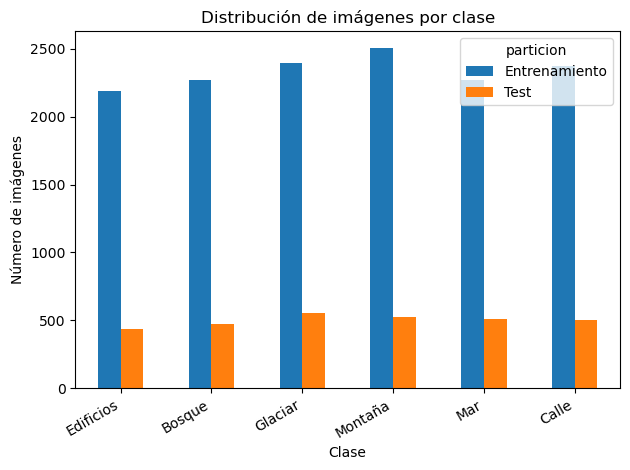

In [29]:
# Creamos la tabla a partir del conjunto limpio.
tabla = pd.crosstab(
    datos_limpios['clase'],
    datos_limpios['particion']
).reindex(
    index=CLASES,
    columns=['train', 'test'],
    fill_value=0
)

# Calculamos el total de imágenes y los porcentajes por clase.
tabla['total'] = tabla[['train', 'test']].sum(axis=1)

tabla['porcentaje_total'] = (
    100 * tabla['total'] / tabla['total'].sum()
).round(2)

for parte in ['train', 'test']:
    tabla[f'porcentaje_{parte}'] = (
        100 * tabla[parte] / tabla[parte].sum()
    ).round(2)

display(tabla)

# Comparamos el tamaño de la clase mayoritaria y la minoritaria.
ratio = tabla['total'].max() / tabla['total'].min()

print('Imágenes del conjunto limpio:', len(datos_limpios))
print('Clases:', datos_limpios['clase'].nunique())
print('Relación mayoritaria/minoritaria:', round(ratio, 2))

# Representamos las imágenes de entrenamiento y test por clase.
ax = (
    tabla[['train', 'test']]
    .rename(
        index=NOMBRES,
        columns={
            'train': 'Entrenamiento',
            'test': 'Test'
        }
    )
    .plot.bar()
)

ax.set_title('Distribución de imágenes por clase')
ax.set_xlabel('Clase')
ax.set_ylabel('Número de imágenes')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()

# Guardamos la gráfica en la carpeta de resultados.
plt.savefig(
    SALIDAS / 'distribucion_dataset_limpio.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

## 1.7. Dimensiones originales y canales
Se analizan las imágenes sin redimensionarlas. El tamaño de entrada de las redes se decidirá en los apartados posteriores.

,ancho,alto,canales
count,17003.0,17003.00,17003.0
mean,150.0,149.91,3.0
std,0.0,1.99,0.0
min,150.0,72.00,3.0
25%,150.0,150.00,3.0
50%,150.0,150.00,3.0
75%,150.0,150.00,3.0
max,150.0,150.00,3.0


,ancho,alto,imagenes
31,150,150,16948
11,150,113,7
10,150,111,3
20,150,135,3
2,150,81,2
19,150,134,2
17,150,131,2
1,150,76,2
15,150,123,2
23,150,141,2


Imágenes analizadas: 17003
Resoluciones diferentes: 32


,modo,canales,formato,imagenes
0,RGB,3,JPEG,17003


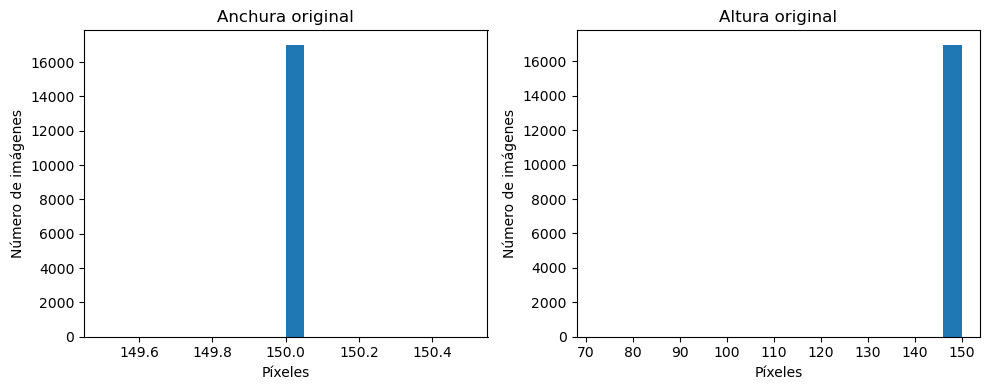

In [30]:
# Contamos las imágenes de cada resolución y ordenamos por frecuencia.
resoluciones = (
    datos_limpios.groupby(['ancho', 'alto'])
    .size()
    .rename('imagenes')
    .reset_index()
    .sort_values('imagenes', ascending=False)
)

# Mostramos las estadísticas de tamaño y las resoluciones más frecuentes.
display(
    datos_limpios[
        ['ancho', 'alto', 'canales']
    ].describe().round(2)
)

display(resoluciones.head(20))

print('Imágenes analizadas:', len(datos_limpios))
print('Resoluciones diferentes:', len(resoluciones))

# Contamos las imágenes según su modo de color, canales y formato.
caracteristicas = (
    datos_limpios.groupby(['modo', 'canales', 'formato'])
    .size()
    .rename('imagenes')
    .reset_index()
    .sort_values('imagenes', ascending=False)
)

display(caracteristicas)

# Representamos la distribución de anchuras y alturas originales.
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

for eje, campo, titulo in zip(
    ejes,
    ['ancho', 'alto'],
    ['Anchura original', 'Altura original']
):
    eje.hist(datos_limpios[campo], bins=20)
    eje.set_title(titulo)
    eje.set_xlabel('Píxeles')
    eje.set_ylabel('Número de imágenes')

plt.tight_layout()

# Guardamos la gráfica en la carpeta de resultados.
plt.savefig(
    SALIDAS / 'dimensiones_dataset_limpio.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# 1.7. Keras Datasets
Disponibilizar los datasets para ser utilizados en entrenamiento, validación y test

In [6]:
import tensorflow as tf
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomTranslation, RandomZoom, RandomContrast, RandomBrightness

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
RANDOM_SEED = 1234
EPOCHS = 300

# para normalizar las imagenes [0,1]
def preprocess_normalization(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# dataset base con las imagenes para train
train_ds = tf.keras.utils.image_dataset_from_directory(
    carpetas["train"],
    validation_split=0.2,
    subset="training",
    seed=RANDOM_SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

# data augmentation (solo usar en train)
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(factor=0.02, fill_mode="reflect"),
    RandomTranslation(height_factor=0.05, width_factor=0.05, fill_mode="reflect"),
    RandomZoom(height_factor=0.05, width_factor=0.05, fill_mode="reflect"),
    RandomContrast(0.1),
    RandomBrightness(factor=0.05, value_range=(0, 255))
])
def preprocess_data_augmentation(image, label):
    image = data_augmentation(image, training=True )
    return image, label

# dataset de train con data augmentation
train_ds_augmented = (
    train_ds
    .map(preprocess_data_augmentation, num_parallel_calls=tf.data.AUTOTUNE)
)

# dataset base con las imagenes para validación
val_ds = tf.keras.utils.image_dataset_from_directory(
    carpetas["train"],
    validation_split=0.2,
    subset="validation",
    seed=RANDOM_SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

# dataset base con las imagenes para test
test_ds = tf.keras.utils.image_dataset_from_directory(
    carpetas["test"],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


### Verificar los datasets

train


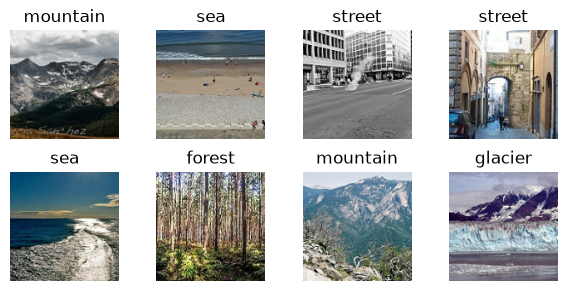

train - augmented


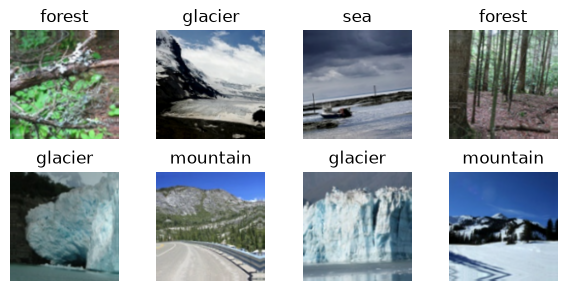

validation


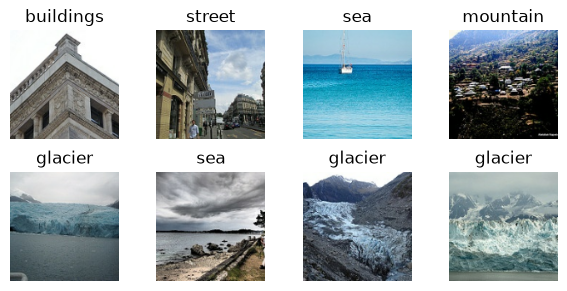

test


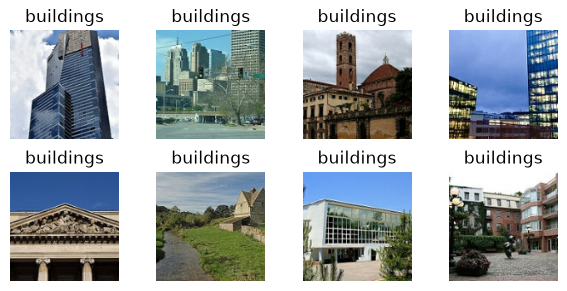

In [7]:
import matplotlib.pyplot as plt

def plot_sample(dataset):
    fig, axes = plt.subplots(2, 4, figsize=(6, 3))
    images, labels = next(iter(dataset.take(1)))
    
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i].numpy() / 255)
        label = class_names[labels[i].numpy()]
        ax.set_title(label)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print('train')
plot_sample(train_ds)
print('train - augmented')
plot_sample(train_ds_augmented)
print('validation')
plot_sample(val_ds)
print('test')
plot_sample(test_ds)

## 2. Modelos de clasificación

In [8]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, GlobalAveragePooling2D, BatchNormalization, Dropout, ReLU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

MODELS = Path.cwd() / 'models'
MODELS.mkdir(parents=True, exist_ok=True)
    

## 2.1 Modelo Base

Clase base donde se implementarán los métodos que se reutilizarán en el resto de las implementaciones
* build: Crea el Model
* train: Entrena el modelo
* load: Recupera los pesos e imagen de resultados
* save: Almacena los pesos e imagen de resultados
* plot_history: Crea la imagen del entrenamiento
* show_history: Muestra la imagen del entrenamiento
* evaluate: Evalua el modelo con el dataset de test
* display_confusion_matrix: Construye la matriz de confusión
* print_classification_report: Imprime las métricas



In [9]:
class base_model:
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        self.name = name
        self.epochs = epochs
        self.batch_size = batch_size
        self.train_ds = train_ds
        self.val_ds = val_ds
        self.test_ds = test_ds
        self.model = None
        
    def build(self):
        raise Exception("Implementar build")

    def train(self):
        # callback para que pare si no mejora en 20 epochs
        early_stopping = EarlyStopping(monitor="val_accuracy", patience=20, mode="max", restore_best_weights=True)
        # callback para que reduzca el learningrate si no mejora en 10 epochs
        reduce_lr = ReduceLROnPlateau(monitor="val_accuracy", mode="max", factor=0.1, patience=10, min_delta=1e-6, cooldown=1, min_lr=1e-10, verbose=0)
        # entrenar
        history = self.model.fit(x = self.train_ds, 
                                 validation_data=self.val_ds,
                                 epochs=self.epochs, 
                                 batch_size = self.batch_size, 
                                 callbacks=[early_stopping, reduce_lr])
        # almacenar el mejor modelo (solo pesos)
        self.model.save_weights(MODELS / f"{self.name}.weights.h5")
        # dibujar metricas
        self.plot_history(history)

    def load(self):
        # verificar que esté construido
        if self.model is None:
            self.build()
        pesos = MODELS / f"{self.name}.weights.h5"
        if os.path.exists(pesos):
            # cargar los pesos
            self.model.load_weights(pesos)
            return True
        return False

    def plot_history(self, H):
        epochs = len(H.history["loss"])
        plt.style.use("ggplot")
        plt.figure()
        plt.plot(np.arange(0, epochs), H.history["loss"], label="train_loss")
        plt.plot(np.arange(0, epochs), H.history["val_loss"], label="val_loss")
        plt.plot(np.arange(0, epochs), H.history["accuracy"], label="train_acc")
        plt.plot(np.arange(0, epochs), H.history["val_accuracy"], label="val_acc")
        plt.title("Training Loss and Accuracy")
        plt.xlabel("Epoch #")
        plt.ylabel("Loss/Accuracy")
        plt.legend()
        plt.savefig(MODELS / f"{self.name}.png")
        plt.close()

    def show_history(self):
        # cargar y dibujar la imagen
        image = Image.open(MODELS / f"{self.name}.png")
        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.axis('off')
        plt.show()

    def evaluate(self):
        y_true = np.concatenate([labels.numpy() for images, labels in self.test_ds])
        y_pred_prob = self.model.predict(self.test_ds)
        y_pred = np.argmax(y_pred_prob, axis=1)
        return y_true, y_pred

    def display_confusion_matrix(self, y_true, y_pred):
        cm = confusion_matrix(y_true, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
        fig, ax = plt.subplots(figsize=(6, 6))
        disp.plot(
            ax=ax,
            cmap='Blues',
            values_format='d',
            colorbar=False
        )
        plt.title(f"Matriz de Confusión - {self.name}")
        plt.tight_layout()
        plt.show()

    def print_classification_report(self, y_true, y_pred):
        print(classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            digits=4
        ))
                

## 2.2 Modelo CNN Simple


In [10]:
class simple_CNN_model(base_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        # se requiere normalización
        train_ds = (
            train_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(batch_size * 5)
            .prefetch(tf.data.AUTOTUNE)
        )
        # se requiere normalización
        val_ds = (
            val_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )
        # se requiere normalización
        test_ds = (
            test_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name, 
                                               epochs = epochs, 
                                               batch_size = batch_size, 
                                               train_ds = train_ds, 
                                               val_ds = val_ds,
                                               test_ds = test_ds)

    def build(self):
        inputs = Input(shape=(IMG_SIZE + (3,)))
    
        # CNN
        x = Conv2D(32, 3, activation='relu')(inputs)
        x = MaxPooling2D()(x)
    
        x = Conv2D(64, 3, activation='relu')(x)
        x = MaxPooling2D()(x)
    
        x = Conv2D(128, 3, activation='relu')(x)
        x = GlobalAveragePooling2D()(x)
    
        x = Dense(64, activation='relu')(x)
    
        outputs = Dense(len(class_names), activation='softmax')(x)
        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()
   


In [11]:
# version simple CNN
simple_CNN = simple_CNN_model(name = "simple_CNN",
                              epochs=EPOCHS, 
                              batch_size=BATCH_SIZE, 
                              train_ds = train_ds, 
                              val_ds = val_ds,
                              test_ds = test_ds
                            )
simple_CNN.build()

Model: "simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             390 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

C:\Andres\VIU\07MIAR\venv\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


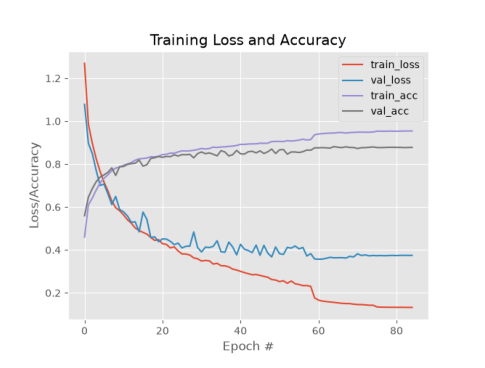

In [12]:
# Train
if not simple_CNN.load():
    simple_CNN.train()
simple_CNN.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step


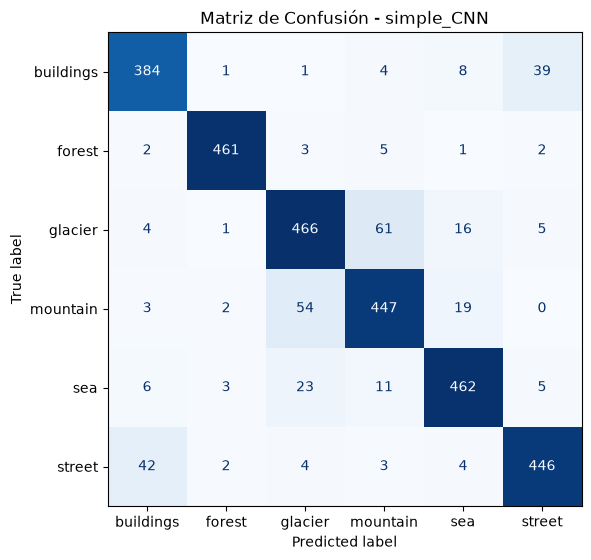

              precision    recall  f1-score   support

   buildings     0.8707    0.8787    0.8747       437
      forest     0.9809    0.9726    0.9767       474
     glacier     0.8457    0.8427    0.8442       553
    mountain     0.8418    0.8514    0.8466       525
         sea     0.9059    0.9059    0.9059       510
      street     0.8974    0.8902    0.8938       501

    accuracy                         0.8887      3000
   macro avg     0.8904    0.8902    0.8903      3000
weighted avg     0.8889    0.8887    0.8888      3000



In [13]:
# Evaluar
y_true, y_pred = simple_CNN.evaluate()
# Matriz de confusion
simple_CNN.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNN.print_classification_report(y_true, y_pred)

## 2.3 Modelo CNN Simple: Data Agumentation

In [350]:
# version simple CNN con Data Augmentation
simple_CNN_aug = simple_CNN_model(name = "simple_CNN_augmented",
                                  epochs=EPOCHS, 
                                  batch_size=BATCH_SIZE, 
                                  train_ds = train_ds_augmented, 
                                  val_ds = val_ds,
                                  test_ds = test_ds)
simple_CNN_aug.build()

Model: "simple_CNN_augmented"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_99 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_216 (Conv2D)             │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_142               │ (None, 63, 63, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_217 (Conv2D)             │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_143               │ (None, 30, 30, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_218 (Conv2D)             │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_70     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_140 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_141 (Dense)               │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

/home/andres/07MIAR/venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_69', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


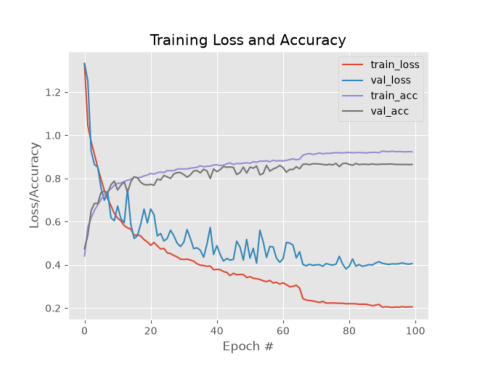

In [351]:
# Train
if not simple_CNN_aug.load():
    simple_CNN_aug.train()
simple_CNN_aug.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


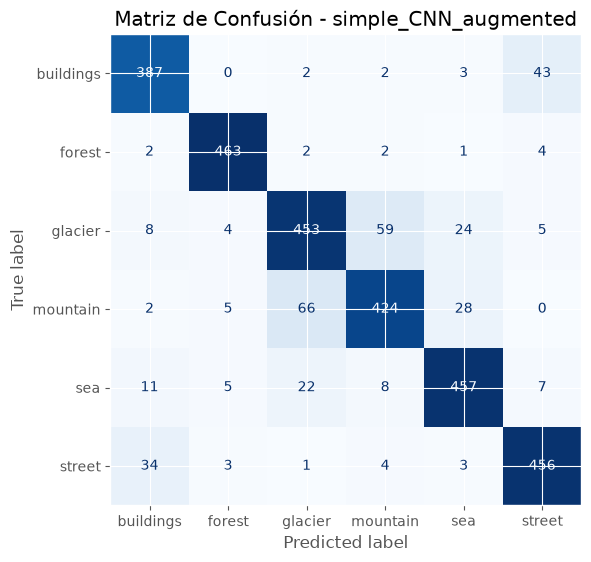

              precision    recall  f1-score   support

   buildings     0.8716    0.8856    0.8785       437
      forest     0.9646    0.9768    0.9706       474
     glacier     0.8297    0.8192    0.8244       553
    mountain     0.8497    0.8076    0.8281       525
         sea     0.8857    0.8961    0.8908       510
      street     0.8854    0.9102    0.8976       501

    accuracy                         0.8800      3000
   macro avg     0.8811    0.8826    0.8817      3000
weighted avg     0.8794    0.8800    0.8796      3000



In [352]:
# Evaluar
y_true, y_pred = simple_CNN_aug.evaluate()
# Matriz de confusion
simple_CNN_aug.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNN_aug.print_classification_report(y_true, y_pred)

## 2.4 Modelo CNN Simple v2: Regularización

* Dropout
* BatchNormalization
* Regularización L2


In [361]:
class simple_CNNv2_model(simple_CNN_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds, dropout_rate = 0.2):
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name, 
                                               epochs = epochs, 
                                               batch_size = batch_size, 
                                               train_ds = train_ds, 
                                               val_ds = val_ds,
                                               test_ds = test_ds)
        self.dropout_rate = dropout_rate

    def build(self):
        inputs = Input(shape=(IMG_SIZE + (3,)))
    
        # CNN
        x = Conv2D(32, 3, kernel_regularizer=l2(1e-6))(inputs)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPooling2D()(x)
        x = Dropout(self.dropout_rate)(x)
    
        x = Conv2D(64, 3, kernel_regularizer=l2(1e-6))(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPooling2D()(x)
        x = Dropout(self.dropout_rate)(x)
    
        x = Conv2D(128, 3, kernel_regularizer=l2(1e-6))(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = GlobalAveragePooling2D()(x)
        x = Dropout(self.dropout_rate)(x)

        x = Dense(64, activation='relu', kernel_regularizer=l2(1e-6))(x)
        x = Dropout(self.dropout_rate)(x)
    
        outputs = Dense(len(class_names), activation='softmax', kernel_regularizer=l2(1e-6))(x)
        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()

In [365]:
# version simple CNN v2 con regularización
simple_CNNv2 = simple_CNNv2_model(name = "simple_CNNv2",
                                  epochs=EPOCHS, 
                                  batch_size=BATCH_SIZE, 
                                  train_ds = train_ds_augmented, 
                                  val_ds = val_ds,
                                  test_ds = test_ds)
simple_CNNv2.build()

Model: "simple_CNNv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_103 (InputLayer)    │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_228 (Conv2D)             │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_150               │ (None, 63, 63, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_46 (Dropout)            │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_229 (Conv2D)             │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_151               │ (None, 30, 30, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_230 (Conv2D)             │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_74     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_48 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_148 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_49 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_149 (Dense)               │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,790 (401.52 KB)

 Trainable params: 102,342 (399.77 KB)

 Non-trainable params: 448 (1.75 KB)

/home/andres/07MIAR/venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_73', because it has 2 variables whereas the saved optimizer has 34 variables. 
  saveable.load_own_variables(store)


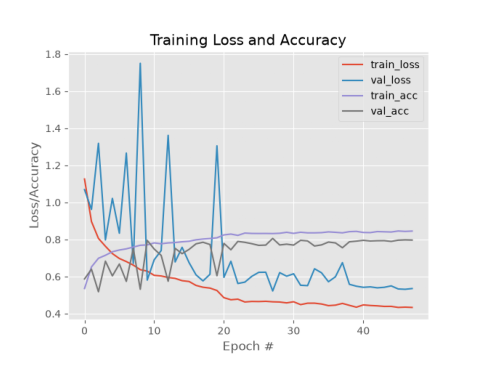

In [366]:
# train
if not simple_CNNv2.load():
    simple_CNNv2.train()
simple_CNNv2.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


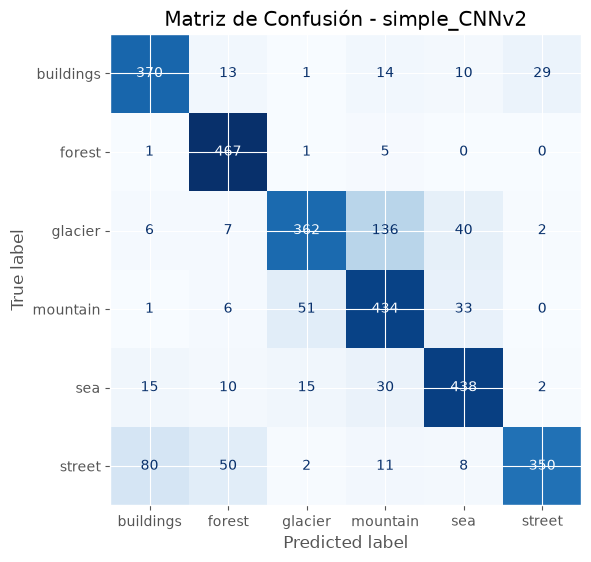

              precision    recall  f1-score   support

   buildings     0.7822    0.8467    0.8132       437
      forest     0.8445    0.9852    0.9094       474
     glacier     0.8380    0.6546    0.7350       553
    mountain     0.6889    0.8267    0.7515       525
         sea     0.8280    0.8588    0.8431       510
      street     0.9138    0.6986    0.7919       501

    accuracy                         0.8070      3000
   macro avg     0.8159    0.8118    0.8074      3000
weighted avg     0.8158    0.8070    0.8047      3000



In [367]:
# Evaluar
y_true, y_pred = simple_CNNv2.evaluate()
# Matriz de confusion
simple_CNNv2.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNNv2.print_classification_report(y_true, y_pred)